# 07 Phase 7: freeze, serving API and demo check

**What this shows.** The frozen bundle (`artifacts/bundle/v1`, sha256 manifest verified at load), the stateless API scoring the saved example applicants, measured latency, the end-to-end browser check (headless Edge, screenshots) and the clean-environment load. The served model is the rule-selected JT (0.05, 2, 0), seed 0, scored in fp32 on CPU with no post-hoc correction. The dashboard states plainly that on this dataset the sequential baseline matched or beat the joint model.

In [1]:
import json, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from fastapi.testclient import TestClient
from api.main import create_app
B = ROOT / 'artifacts' / 'bundle' / 'v1'
man = json.loads((B / 'manifest.json').read_text())
print({k: man[k] for k in man if k not in ('files',)})
print(len(man.get('files', {})), 'files hashed')

C:\Users\Arghyadeep\Desktop\Major Project\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'model_version': 'jt-chosen-0.05-2-0-seed0-v1', 'git_commit': '2976f80fdcda43a1248c87bcbbc262b0fa92f8dc', 'config_hash': '55e1f9c07c81e9cdf5af03705a199629befea0f2b48e49728177c98e9ce4b701', 'seeds': [0, 1, 2], 'served_seed': 0, 'lambdas': [0.05, 2.0, 0.0], 'risk_bands': {'low_max': 0.08072788426695904, 'medium_max': 0.19436781101874467}, 'risk_band_rule': 'Low: below the training default rate; Medium: above it but below the flag threshold (validation 90th percentile); High: at or above the flag threshold', 'parity_bf16_vs_fp32_max_abs_diff_on_test_pool': 0.0018425724290673795, 'bundle_sha': 'c3bb9c7254d5a973c46edab138c28e508e2eed7f5a76d502d0bebcdd6265ee56'}
19 files hashed


## 1. Load the bundle and score the example applicants

In [2]:
c = TestClient(create_app(B)).__enter__()
print(c.get('/health').json())
ex = c.get('/examples').json(); rows = ex if isinstance(ex, list) else ex.get('examples', ex)
res = [c.post('/predict', json=(r.get('record', r))).json() for r in rows]
pd.DataFrame([{'probability': round(r['probability'], 4), 'band': r.get('risk_band')} for r in res])

{'status': 'ok', 'model_version': 'jt-chosen-0.05-2-0-seed0-v1', 'bundle_sha': 'c3bb9c7254d5a973c46edab138c28e508e2eed7f5a76d502d0bebcdd6265ee56'}


,probability,band
0,0.0502,Low
1,0.1407,Medium
2,0.1238,Medium
3,0.0534,Low
4,0.0310,Low
5,0.0380,Low
6,0.1169,Medium
7,0.0174,Low


## 2. Latency (measured here, 3 warm-up calls discarded)

In [3]:
rec = rows[0].get('record', rows[0])
for _ in range(3): c.post('/predict', json=rec)
t = []
for _ in range(100):
    s = time.perf_counter(); c.post('/predict', json=rec); t.append((time.perf_counter() - s) * 1000)
t = np.array(t)
s = time.perf_counter(); r = c.post('/explain', json=rec); ex_ms = (time.perf_counter() - s) * 1000
print(f'/predict ms: p50 {np.percentile(t, 50):.1f}, p95 {np.percentile(t, 95):.1f} (limit 300)')
print(f'/explain ms: {ex_ms:.0f} (predict + explain limit 3000), status {r.status_code}')

C:\Users\Arghyadeep\Desktop\Major Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/predict ms: p50 15.2, p95 16.9 (limit 300)
/explain ms: 486 (predict + explain limit 3000), status 200


## 3. Fail-closed check: the verifier rejects a tampered bundle (see tests/test_api.py, 503 MODEL_NOT_READY)

In [4]:
import subprocess
out = subprocess.run([sys.executable, '-m', 'pytest', 'tests/test_api.py', '-q', '-x', '-p', 'no:cacheprovider'], cwd=ROOT, capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

26 passed, 2 warnings in 7.74s


## 4. End-to-end browser check (headless Edge, `scripts/ui_screenshots.py`)

{
 "browser": "msedge.exe",
 "steps": {
  "form_built": true,
  "example_loaded": true,
  "screenshot_form": "01_form.png",
  "result_page": true,
  "probability_text": "11.7%",
  "band_text": "Medium risk",
  "shap_chart_drawn": true,
  "matched_panel": true,
  "screenshot_result": "02_result.png",
  "dashboard_loaded": true,
  "charts_drawn": true,
  "slider_nearest": "Nearest sweep point: lambda_f 0.25, lambda_c 2, lambda_a 0AUC-ROC 0.7288, AUC-PR 0.1967, EOD 0.0199, worst-group ECE 0.0",
  "honest_banner": "On this dataset the sequential baseline (class weights + prior correction + gender-blind fairness step) matched or beat the joint model.",
  "disclaimer_on_all_pages": true,
  "screenshot_dashboard": "03_dashboard.png"
 }
}
01_form.png


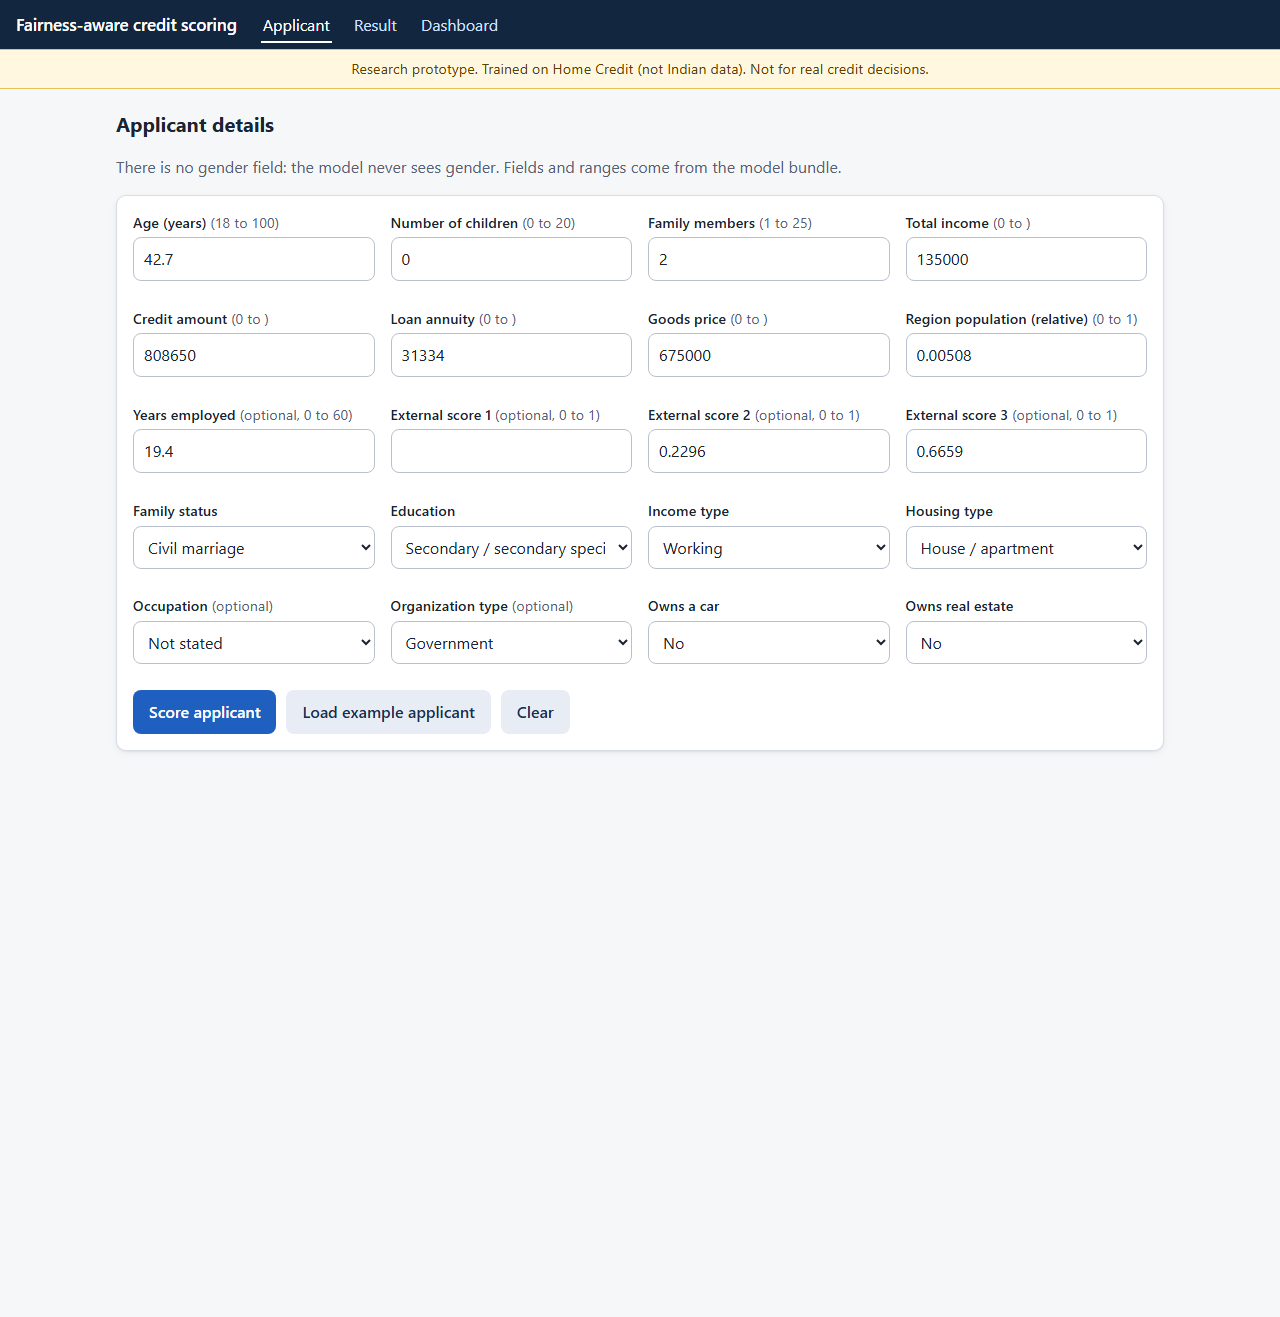

02_result.png


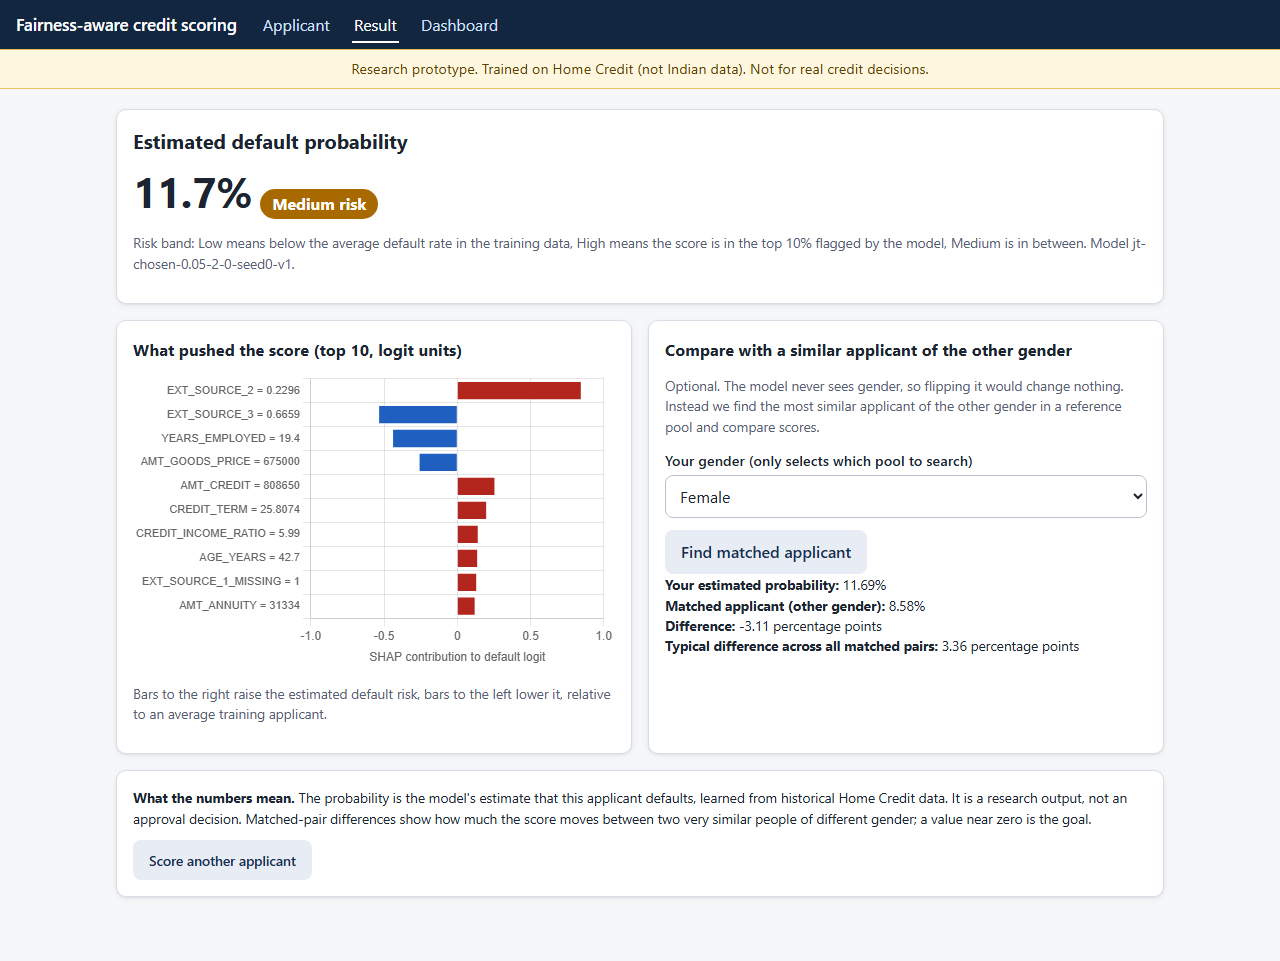

03_dashboard.png


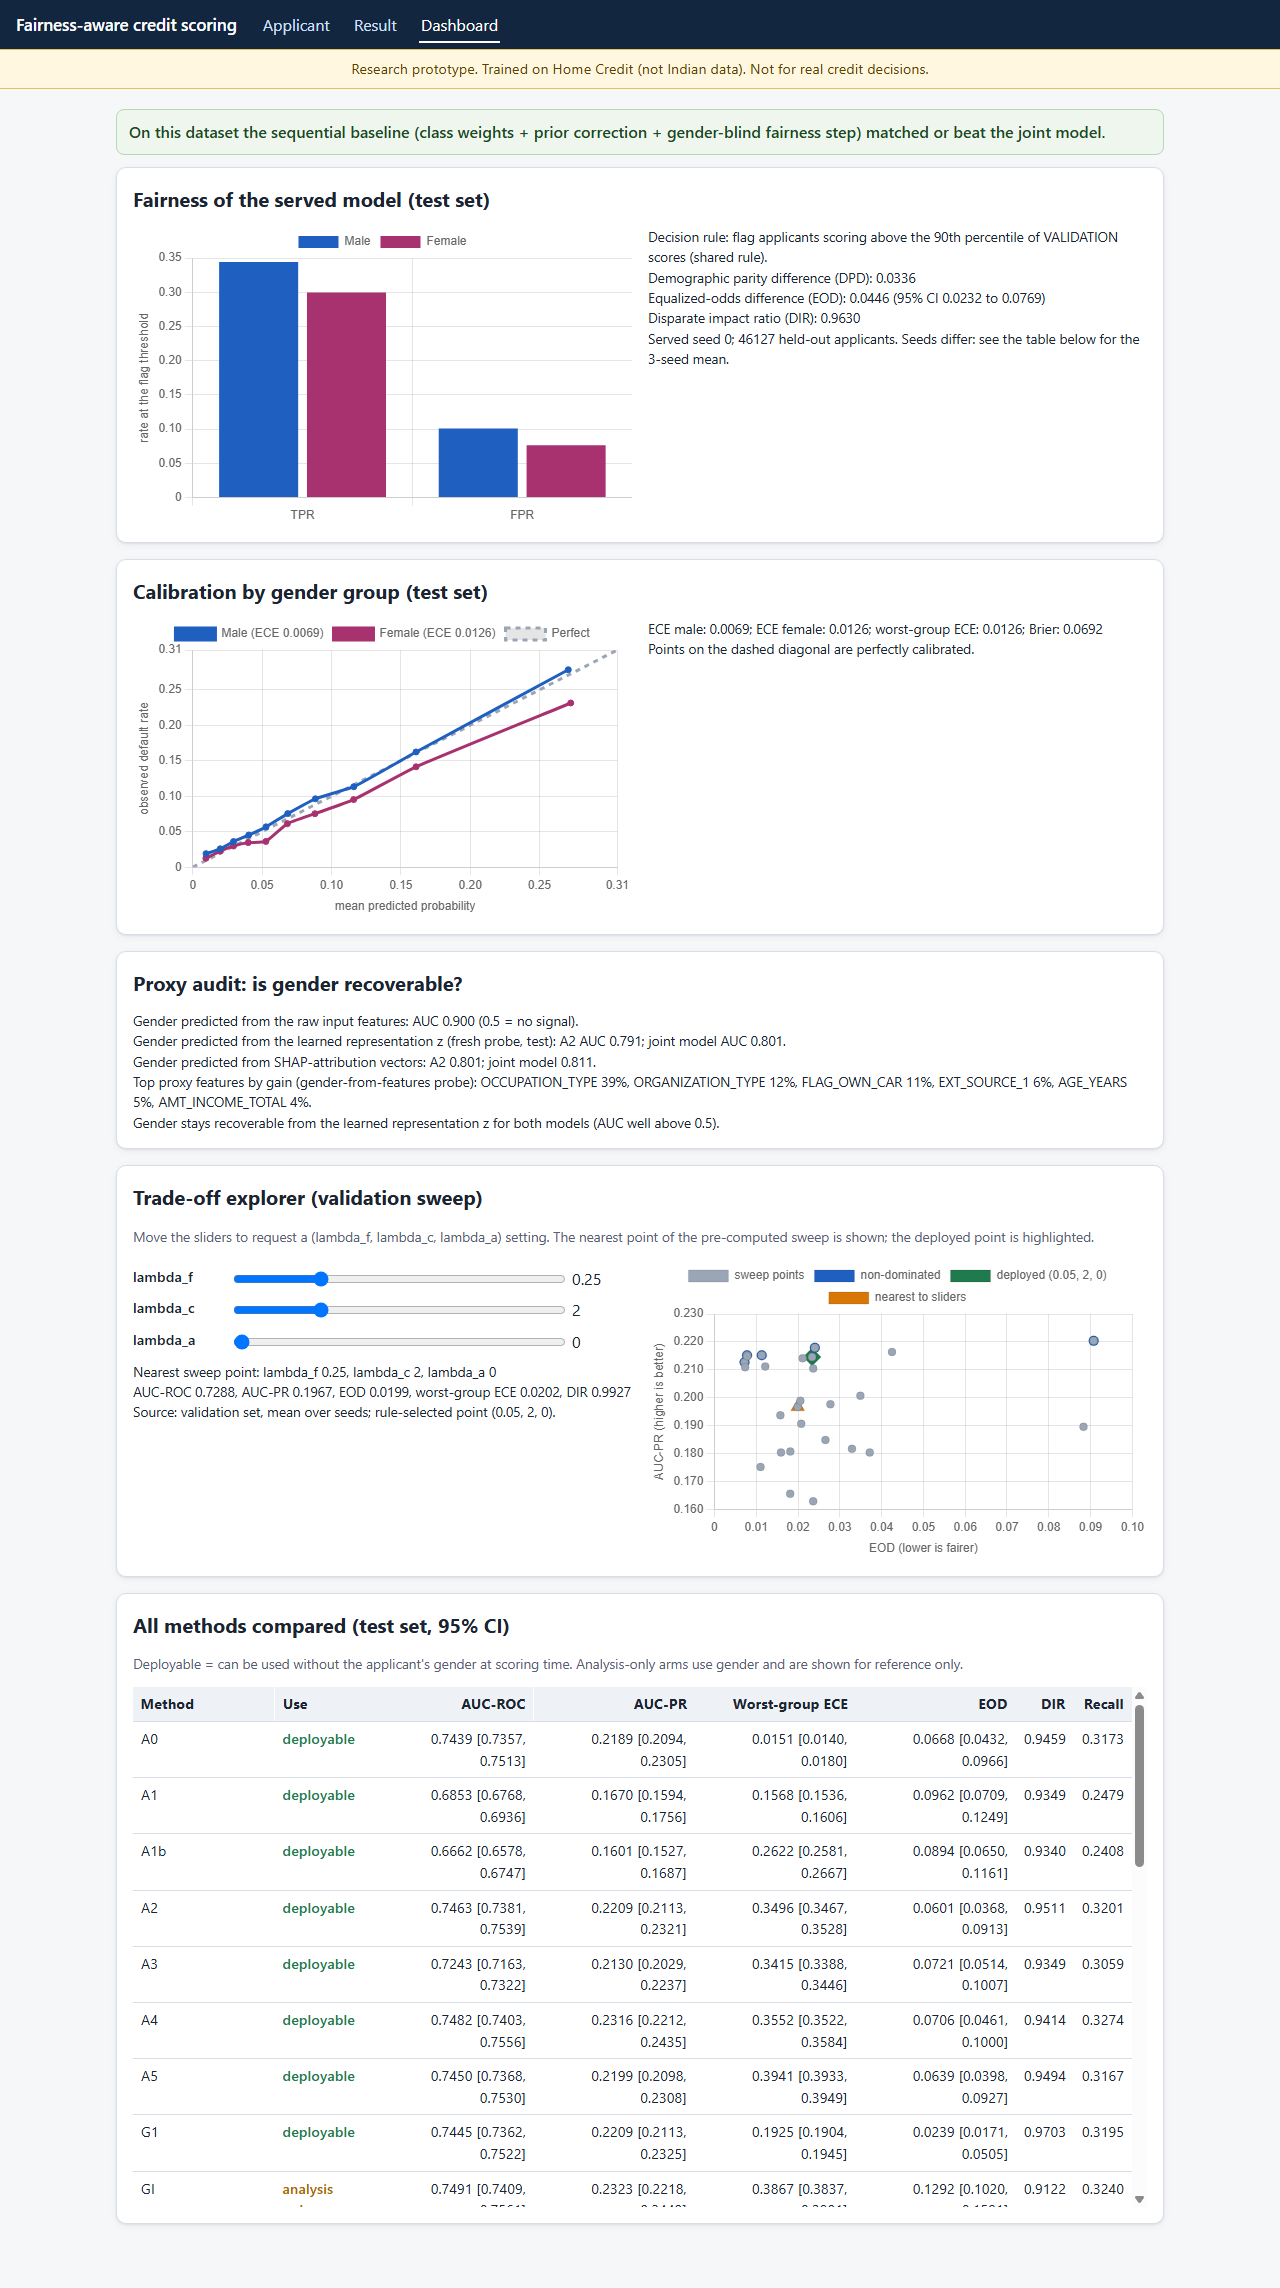

In [5]:
ui = json.loads((ROOT / 'artifacts' / 'ui' / 'ui_check.json').read_text())
print(json.dumps(ui, indent=1))
for n in ('01_form.png', '02_result.png', '03_dashboard.png'):
    print(n); display(Image(filename=str(ROOT / 'artifacts' / 'ui' / n), width=700))

## 5. Clean-environment load

A fresh venv with serving dependencies only (fastapi, uvicorn, pydantic, numpy, pandas, scikit-learn, scipy, joblib, PyYAML, shap, torch; no lightgbm, fairlearn, mlflow, matplotlib or jupyter) loaded the same bundle and returned identical probabilities for the 8 example applicants (checked to 6 decimals against the main venv).